In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
import shap
from sklearn.preprocessing import StandardScaler, MinMaxScaler

In [3]:
from google.colab import drive
#drive.mount('/content/drive')
drive.mount("/content/drive", force_remount=True)

Mounted at /content/drive


In [4]:
data = pd.read_csv("/content/drive/My Drive/SHAP_multipredictors/Guild/Grassland/4x4/Raster_extracted_4x4_Raster_extracted_Pred_ GRSP .csv")


y = data['Predicted']

# List of individual predictors
predictors = {
    "Shrubland_percentage": data.iloc[:, 4],
    "precip_average": data.iloc[:, 5],
    "Grassland_percentage": data.iloc[:, 6],
    "Forest_percentage": data.iloc[:, 7],
    "tmax_average": data.iloc[:, 8],
    "VarDHI_32x32": data.iloc[:, 9],
    "CumDHI_32x32": data.iloc[:, 10],
    "DEM": data.iloc[:, 11]
}


# Creating DataFrame for predictors
X = pd.DataFrame(predictors)

## Removing outliers
# Function to remove outliers using 5th and 95th percentiles
#def remove_outliers_percentile(df, lower_percentile=5, upper_percentile=95):
#    lower_bound = df.quantile(lower_percentile / 100.0)
#    upper_bound = df.quantile(upper_percentile / 100.0)
#    return df[(df >= lower_bound) & (df <= upper_bound)].dropna()

# Apply outlier removal
#X_cleaned = remove_outliers_percentile(X)

# Remove corresponding y values for consistency
#y = y.loc[X_cleaned.index]

# Selecting correct predictors for feature matrix (X)
#X = pd.concat([X_cleaned["Shrubland_percentage"],X_cleaned["precip_average"],X_cleaned["Grassland_percentage"],X_cleaned["Forest_percentage"],X_cleaned["tmax_average"],X_cleaned["CumDHI_32x32"], X_cleaned["DEM"], X_cleaned["VarDHI_32x32"]], axis=1)
#X = pd.concat([X_cleaned["tmax_average"],X_cleaned["precip_average"],X_cleaned["CumDHI_32x32"],X_cleaned["VarDHI_32x32"]], axis=1)

# Normalize the predictor variables
scaler = StandardScaler()
#X_scaled = scaler.fit_transform(X)

#scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

# Convert back to DataFrame to maintain structure
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Create and train the Random Forest model
model = RandomForestRegressor(n_estimators=1000, random_state=42)
model.fit(X_train, y_train)

# Make predictions on the test set
#y_pred = model.predict(X_test)

# Evaluate the model's performance
#accuracy = model.score(X_test, y_test)
#print('Accuracy:', accuracy)

RandomForestRegressor(n_estimators=1000, random_state=42)

In [9]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
# Make predictions on the test set
y_pred = model.predict(X_test)

# Calculate R² Score
r2 = r2_score(y_test, y_pred)
print(f'R² Score: {r2:.4f}')

R² Score: 0.8343


In [7]:
gini_imp = pd.Series(model.feature_importances_, index=X.columns, name="gini_importance")
gini_imp

,gini_importance
Shrubland_percentage,0.865729
precip_average,0.038551
Grassland_percentage,0.008154
Forest_percentage,0.007188
tmax_average,0.027921
VarDHI_32x32,0.007999
CumDHI_32x32,0.021712
DEM,0.022745


In [ ]:
X_scaled[200:210]

,Shrubland_percentage,precip_average,Grassland_percentage,Forest_percentage,tmax_average,VarDHI_32x32,CumDHI_32x32,DEM
200,-0.633427,0.920302,0.888987,-0.800807,-0.936889,0.152127,0.356598,-0.212578
201,-0.233936,0.941145,0.112798,-0.800807,-0.894699,0.939899,0.280520,-0.151836
202,-0.226460,0.967603,1.820414,-0.800807,-0.894699,-0.793199,0.280520,0.062603
203,-0.758265,1.065008,-0.663391,0.250493,-0.594303,0.624790,-0.044646,0.631408
204,-0.625704,1.086502,-0.663391,0.851236,-0.594303,-0.005428,-0.044646,0.723873
205,-0.887046,1.053517,-0.663391,0.400679,-0.594303,0.467236,-0.044646,0.667312
206,-0.781721,1.066887,-0.663391,-0.049879,-0.594303,0.939899,-0.044646,0.651573
207,-1.241268,0.573853,-0.663391,-0.800807,-1.049344,1.727670,0.685193,-0.860322
208,-0.917609,0.505152,-0.663391,-0.800807,-1.049344,1.727670,0.685193,-1.319940
209,-0.962878,0.535913,-0.663391,-0.800807,-1.023174,1.727670,0.587891,-1.164275


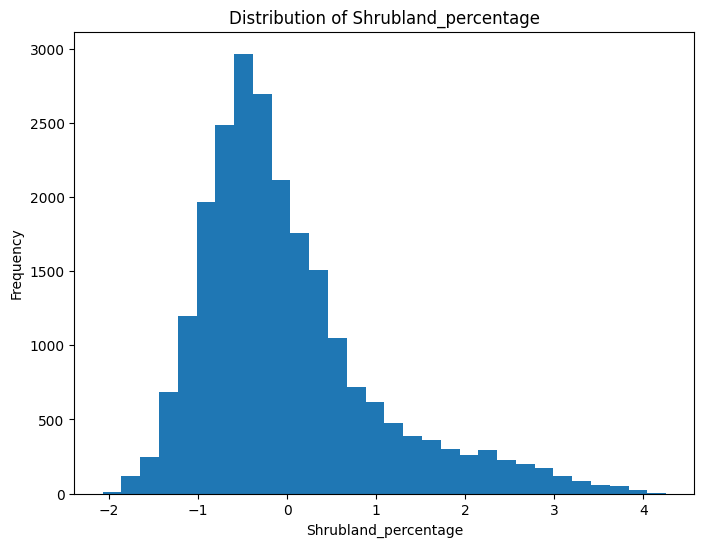

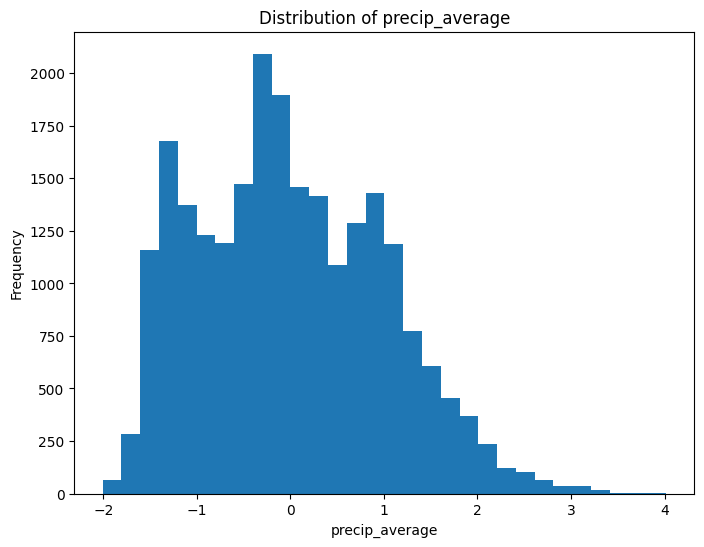

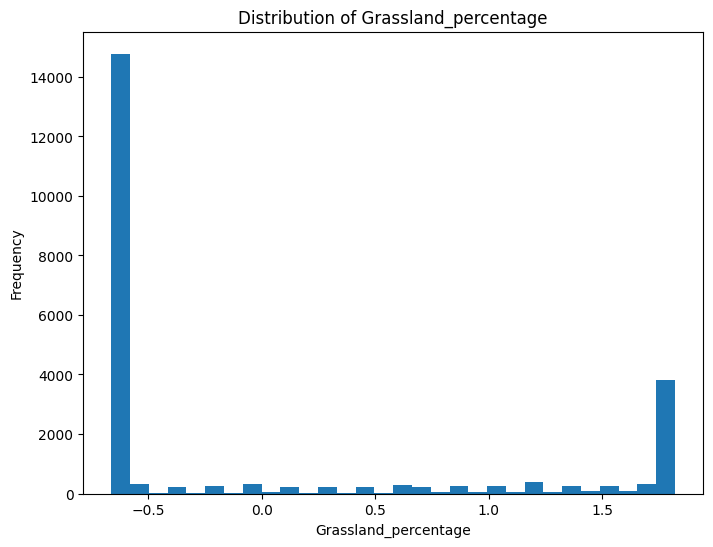

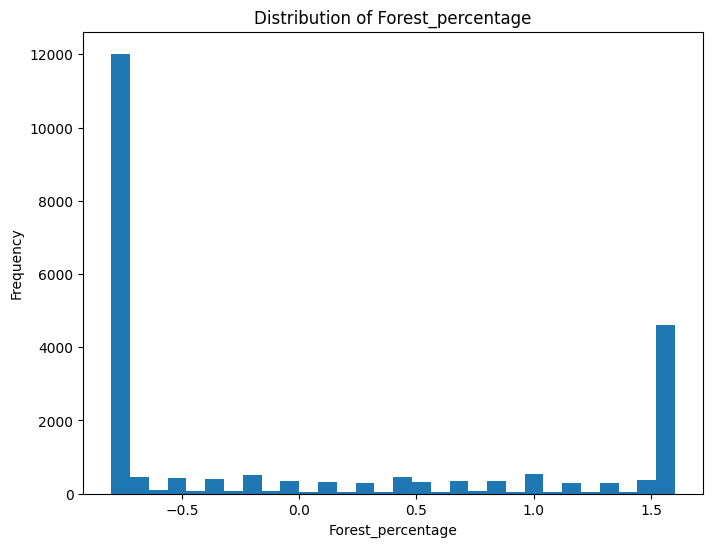

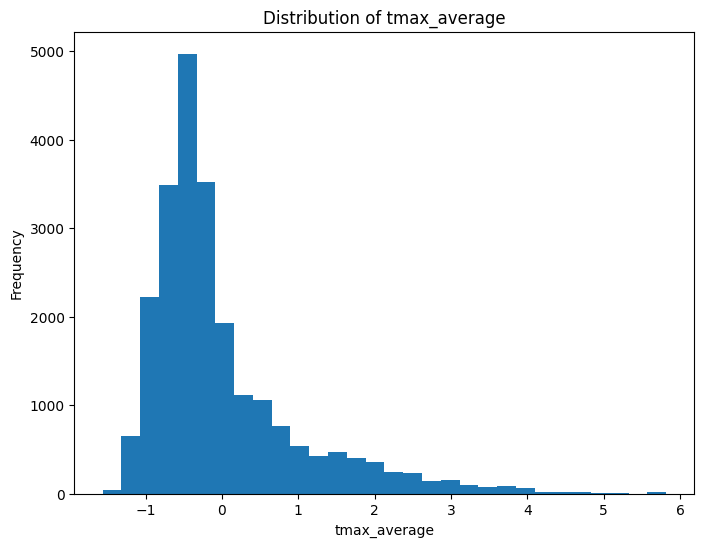

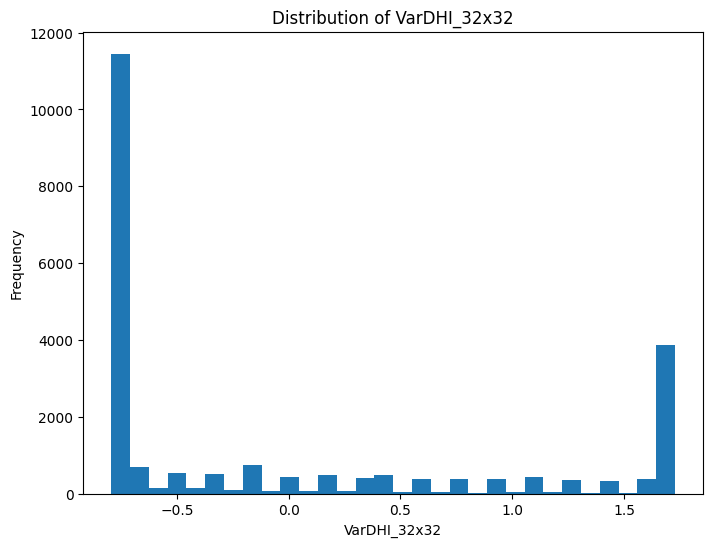

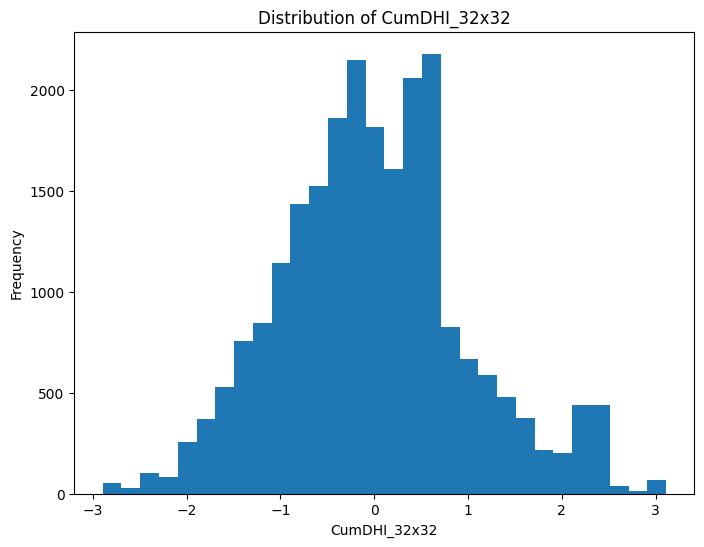

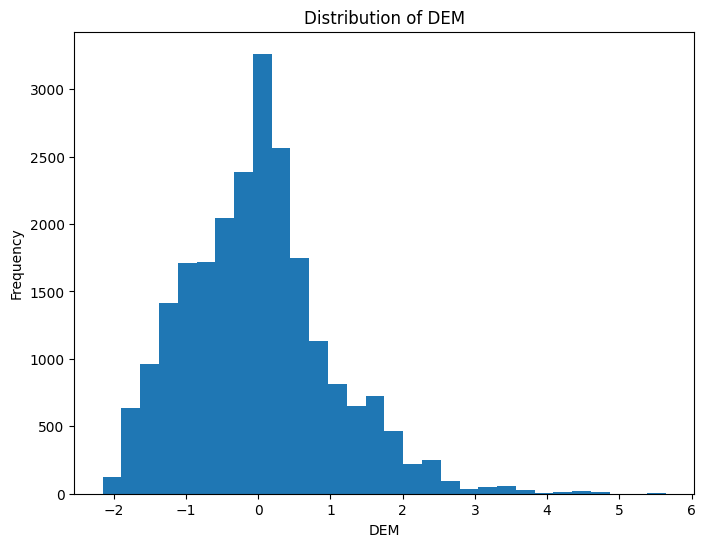

In [ ]:
# prompt: plot the distribution of each column in X_scaled

import matplotlib.pyplot as plt

# Plot the distribution of each column in X_scaled
for column in X_scaled.columns:
    plt.figure(figsize=(8, 6))
    plt.hist(X_scaled[column], bins=30)
    plt.title(f'Distribution of {column}')
    plt.xlabel(column)
    plt.ylabel('Frequency')
    plt.show()


In [ ]:
# Make predictions on the test set
y_pred = model.predict(X_test)

# Evaluate the model's performance
accuracy = model.score(X_test, y_test)
print('Accuracy:', accuracy)

Accuracy: 0.8342744981688108


In [ ]:
# Define the explainer using the regression model
explainer = shap.TreeExplainer(model)

# Create the function to predict using the model
f = lambda x: model.predict(x)

# Now, compute SHAP values for the regression model
shap_values = explainer.shap_values(X)  # Replace X_test with your test data

import pickle

# Save the SHAP values
with open('Z:\\aanand37\\from_GAIA\\aa_Chapter 1\\IMBCR\\Abundance\\SHAP\\Woodland\\shap_values_YBCH.pkl', 'wb') as f:
    pickle.dump(shap_values, f)


In [ ]:
explainer = shap.TreeExplainer(model)

# Create the function to predict using the model
f = lambda x: model.predict(x)

# Now, compute SHAP values for the regression model
shap_values = explainer.shap_values(X)  # Replace X_test with your test data


AssertionError: Feature and SHAP matrices must have the same number of rows!

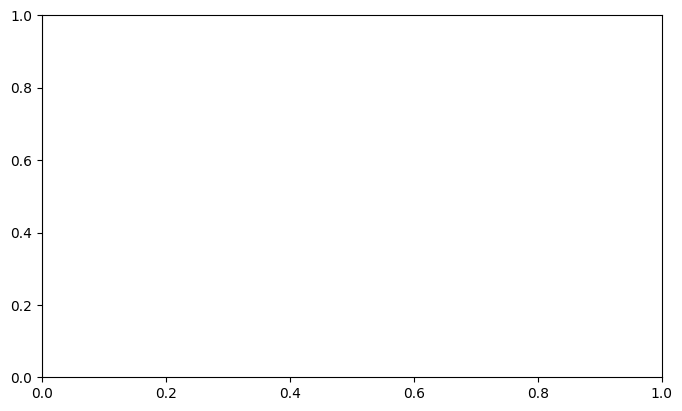

In [ ]:
# Generate SHAP summary plot
plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values, X, show=False)
plt.gcf().axes[-1].set_ylabel("Abundance", fontsize=12)  # Change legend label to "Abundance"
plt.show()

In [ ]:
species_list = ["a","b"]
# List of individual predictors
predictors = {
    "Shrubland_percentage": data.iloc[:, 4],
    "precip_average": data.iloc[:, 5],
    "Grassland_percentage": data.iloc[:, 6],
    "Forest_percentage": data.iloc[:, 7],
    "tmax_average": data.iloc[:, 8],
    "VarDHI_32x32": data.iloc[:, 9],
    "CumDHI_32x32": data.iloc[:, 10],
    "DEM": data.iloc[:, 11]
}

# Iterate over each individual predictor group
for predictor_name, predictor_data in predictors.items():
    print(f"Processing species: {species_list}, predictor: {predictor_name}")


Processing species: ['a', 'b'], predictor: Shrubland_percentage
Processing species: ['a', 'b'], predictor: precip_average
Processing species: ['a', 'b'], predictor: Grassland_percentage
Processing species: ['a', 'b'], predictor: Forest_percentage
Processing species: ['a', 'b'], predictor: tmax_average
Processing species: ['a', 'b'], predictor: VarDHI_32x32
Processing species: ['a', 'b'], predictor: CumDHI_32x32
Processing species: ['a', 'b'], predictor: DEM


Delete below things once done

In [ ]:
!pip install rasterio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 22.2/22.2 MB 22.0 MB/s eta 0:00:00


In [ ]:
import os
import pandas as pd
import rasterio
from rasterio.transform import rowcol

# Load the first CSV file (static file1)
#file1 = "/content/drive/My Drive/SHAP_multipredictors/IMBCR_specieslist_2010_20_final_scaled_with_habitat.csv"
#df1 = pd.read_csv(file1)

# Folder containing the second set of CSV files (dynamic)
csv_folder = "/content/drive/My Drive/SHAP_multipredictors/Guild/Shrubland"

# Folder containing raster files
raster_folder = "/content/drive/My Drive/SHAP_multipredictors/Raster/Raster_4x4"

# Get list of all CSV files in the folder
csv_files = [os.path.join(csv_folder, f) for f in os.listdir(csv_folder) if f.endswith('.csv')]

# Get list of all raster files in the folder
raster_files = [os.path.join(raster_folder, f) for f in os.listdir(raster_folder) if f.endswith('.tif')]

# Process each CSV file
for csv_file in csv_files:
    # Read CSV and select only relevant columns
    points_df = pd.read_csv(csv_file, usecols=['uniqueID', 'PointLatit', 'PointLongi', 'Predicted'])

    # Initialize results DataFrame
    results_df = points_df.copy()

    # Loop through each raster file and extract values
    for raster_file in raster_files:
        raster_name = os.path.splitext(os.path.basename(raster_file))[0]  # Extract raster name
        with rasterio.open(raster_file) as src:
            # Read the raster transformation
            transform = src.transform
            raster_data = src.read(1)  # Read first band

            # Convert lat/lon to raster indices
            rows, cols = zip(*[rowcol(transform, lon, lat) for lon, lat in zip(points_df['PointLongi'], points_df['PointLatit'])])

            # Ensure indices are within raster bounds
            valid_indices = [(0 <= r < src.height and 0 <= c < src.width) for r, c in zip(rows, cols)]

            # Extract raster values, set NaN if out of bounds
            raster_values = [raster_data[r, c] if valid else float('nan') for r, c, valid in zip(rows, cols, valid_indices)]

            # Add raster values as a new column
            results_df[raster_name] = raster_values

    # Define output file name based on input CSV name
    output_file = os.path.join(csv_folder, f"Raster_extracted_4x4_{os.path.basename(csv_file)}")

    # Save extracted data to CSV
    results_df.to_csv(output_file, index=False)

    print(f"Raster values successfully extracted and saved to: {output_file}")


Raster values successfully extracted and saved to: /content/drive/My Drive/SHAP_multipredictors/Guild/Shrubland/Raster_extracted_4x4_Raster_extracted_Pred_ GRFL .csv
Raster values successfully extracted and saved to: /content/drive/My Drive/SHAP_multipredictors/Guild/Shrubland/Raster_extracted_4x4_Raster_extracted_Pred_ LOSH .csv
Raster values successfully extracted and saved to: /content/drive/My Drive/SHAP_multipredictors/Guild/Shrubland/Raster_extracted_4x4_Raster_extracted_Pred_ SATH .csv
Raster values successfully extracted and saved to: /content/drive/My Drive/SHAP_multipredictors/Guild/Shrubland/Raster_extracted_4x4_Raster_extracted_Pred_ WEKI .csv
Raster values successfully extracted and saved to: /content/drive/My Drive/SHAP_multipredictors/Guild/Shrubland/Raster_extracted_4x4_Raster_extracted_Pred_ YEWA .csv


In [ ]:
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import r2_score

#species_list = ["GRSP", "LBCU", "MOBL", "UPSA", "WEME"]  # Grassland
#species_list = ["HAFL","OSFL", "RCKI","WETA","YRWA"]  #Forest
species_list = ["BGGN","CAKI","EABL","PLVI","SAPH"] #woodland
#species_list = ["GRFL","LOSH","WEKI","SATH","YEWA"]  #shrubland
for species in species_list:
  data = pd.read_csv(f"/content/drive/My Drive/SHAP_multipredictors/Guild/Woodland/32x32/Raster_extracted_Raster_extracted_Pred_ {species} .csv")
  y = data['Predicted']
  predictors = data.iloc[:,4:12]

  X = pd.concat([predictors], axis=1)
  scaler = StandardScaler()
  X_scaled = scaler.fit_transform(X)
  X_scaled = pd.DataFrame(X_scaled, columns=X.columns)
  # Split the data into training and testing sets
  X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)
  # Create and train the Random Forest model
  model = RandomForestRegressor(n_estimators=1000, random_state=42)
  model.fit(X_train, y_train)

  y_pred = model.predict(X_test)

  # Evaluate the model's performance
  accuracy = model.score(X_test, y_test)
  print(f'Accuracy {species}:', accuracy)


Accuracy BGGN: 0.6555246467612013
Accuracy CAKI: 0.7154777568026918
Accuracy EABL: 0.5096998600752519
Accuracy PLVI: 0.44375158299669615
Accuracy SAPH: 0.6847190157634404
